# STC Jawwy

In [1]:
"""
Here we install libraries that are not installed by default 
Example:  pyslsb
Feel free to add any library you are planning to use.
"""
!pip install pyxlsb
!pip install scikit-learn
!pip install statsmodels


[notice] A new release of pip is available: 25.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Import the required libraries 
"""
Please feel free to import any required libraries as per your needs
"""
import pandas as pd     # provides high-performance, easy to use structures and data analysis tools
import pyxlsb           # Excel extention to read xlsb files (the input file)
import numpy as np      # provides fast mathematical computation on arrays and matrices

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

ImportError: cannot import name 'SARIMA' from 'statsmodels.tsa.statespace.sarimax' (c:\Users\MrRed\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py)

# Jawwy dataset
The dataset includes total watching hours for customers per day. 

You are required to work on predecting the forecast for the watching hours.

In [3]:
dataframe = pd.read_excel("stc TV Data Set_T2.xlsx",index_col=0)
# Please make a copy of dataset if you are going to work directly and make changes on the dataset
# you can use   df=dataframe.copy()

In [4]:
# check the data shape
dataframe.shape

(86, 2)

In [5]:
# display the first 5 rows 
dataframe.head()

,date_,Total_watch_time_in_houres
0,2018-01-01,1123.551944
1,2018-01-02,1000.129722
2,2018-01-03,881.924444
3,2018-01-04,782.669444
4,2018-01-05,1051.939444


In [6]:
# describe the numeric values in the dataset
dataframe.describe()

,date_,Total_watch_time_in_houres
count,86,86.000000
mean,2018-02-28 17:01:23.720930304,780.817926
min,2018-01-01 00:00:00,562.124722
25%,2018-01-30 06:00:00,707.709653
50%,2018-02-28 12:00:00,763.181389
75%,2018-03-29 18:00:00,840.985278
max,2018-04-30 00:00:00,1123.551944
std,NaN,122.992002


In [7]:
# check if any column has null value in the dataset
dataframe.isnull().any()

date_                         False
Total_watch_time_in_houres    False
dtype: bool

In [8]:
# we import Visualization libraries 
# you can ignore and use any other graphing libraries 
import matplotlib.pyplot as plt # a comprehensive library for creating static, animated, and interactive visualizations
import plotly #a graphing library makes interactive, publication-quality graphs. Examples of how to make line plots, scatter plots, area charts, bar charts, error bars, box plots, histograms, heatmaps, subplots, multiple-axes, polar charts, and bubble charts.
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [9]:
# Setting the date as index
dataframe.set_index('date_', inplace=True)

In [10]:
# Display the dataframe after setting the date as index
dataframe.head()

,Total_watch_time_in_houres
date_,
2018-01-01,1123.551944
2018-01-02,1000.129722
2018-01-03,881.924444
2018-01-04,782.669444
2018-01-05,1051.939444


In [11]:
# show the dataframe
fig = px.line(dataframe,  y="Total_watch_time_in_houres")
fig.show()

In [12]:
"""
TODO using the previous dataset (df) build a prediction model to predict the expected watch time for the next two months
Hint: you can build a forecast model to predict the results
"""

'\nTODO using the previous dataset (df) build a prediction model to predict the expected watch time for the next two months\nHint: you can build a forecast model to predict the results\n'

In [13]:
# create a copy of the dataset to clean the data
df_cleaned = dataframe

# Add missing dates to the index
full_index = pd.date_range(start=df_cleaned.index.min(), end=df_cleaned.index.max(), freq='D')
df_cleaned = df_cleaned.reindex(full_index)

In [14]:
# Interpolate missing values using linear interpolation
df_cleaned['Total_watch_time_in_houres'] = df_cleaned['Total_watch_time_in_houres'].interpolate(method='linear')
display(df_cleaned.head(10))

,Total_watch_time_in_houres
2018-01-01,1123.551944
2018-01-02,1000.129722
2018-01-03,881.924444
2018-01-04,782.669444
2018-01-05,1051.939444
2018-01-06,981.685741
2018-01-07,911.432037
2018-01-08,841.178333
2018-01-09,873.495000
2018-01-10,970.475000


In [ ]:
# Create a SARIMAX model with specified order and seasonal order
model = SARIMAX(
    df_cleaned['Total_watch_time_in_houres'],
    order=(1,1,1),
    seasonal_order=(1,1,1,7)
)

In [17]:
model_fit = model.fit()


In [ ]:
# Add future dates for the next 60 days to the index
future_dates = pd.date_range(
    start=df_cleaned.index[-1] + pd.Timedelta(days=1),
    periods=60,
    freq='D'
)

In [25]:
forecast = model_fit.forecast(
    steps=60
)

In [ ]:
# Create a DataFrame to hold the forecasted values and future dates
forecast_df = pd.DataFrame({
    'Total_watch_time_in_houres': forecast
}, index=future_dates)

In [ ]:
# Combine the original cleaned DataFrame with the forecasted DataFrame
combined_df = pd.concat([
    df_cleaned,
    forecast_df
])

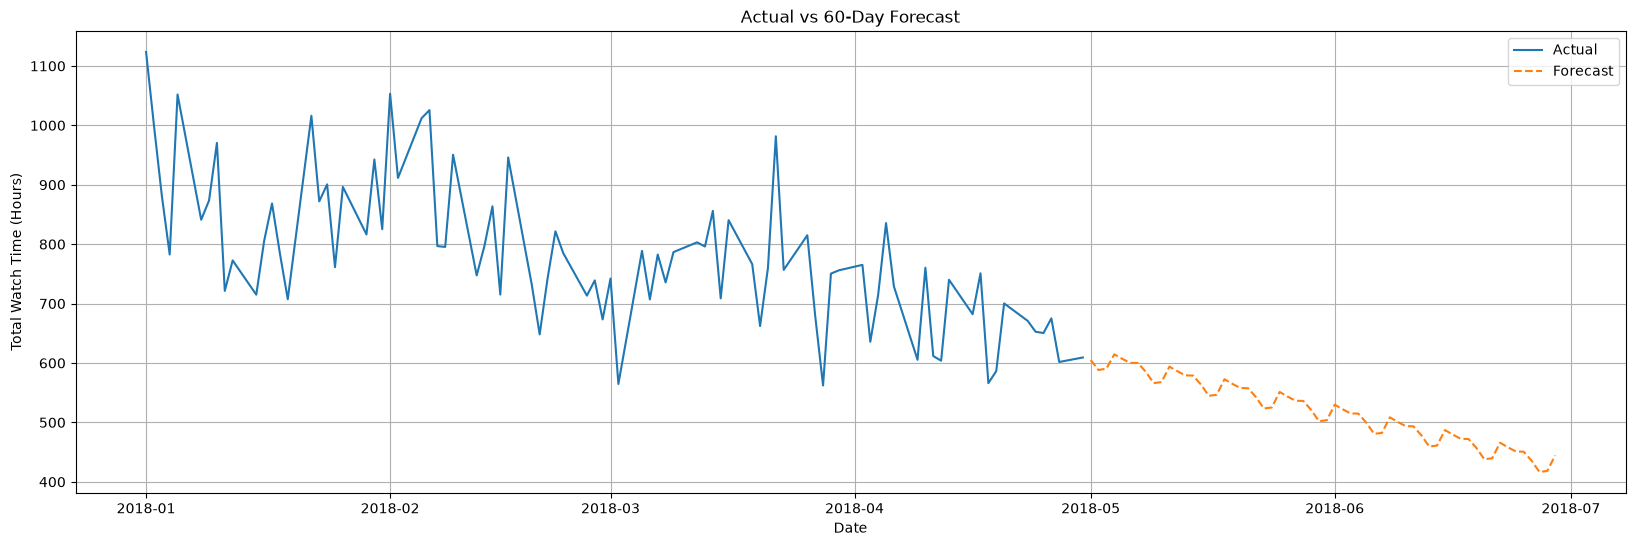

In [ ]:
# show the dataframe with the forecasted values
plt.figure(figsize=(20, 6))

plt.plot(
    df_cleaned.index,
    df_cleaned['Total_watch_time_in_houres'],
    label='Actual'
)

plt.plot(
    forecast_df.index,
    forecast_df['Total_watch_time_in_houres'],
    label='Forecast',
    linestyle='--'
)

plt.xlabel('Date')
plt.ylabel('Total Watch Time (Hours)')
plt.title('Actual vs 60-Day Forecast')
plt.legend()
plt.grid(True)

plt.show()